In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Load Wine Quality Dataset (Red)[span_1](start_span)[span_1](end_span)
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
df_wine = pd.read_csv(url, sep=';')

# Summary statistics and missing values[span_2](start_span)[span_2](end_span)
print("--- Summary Statistics ---")
print(df_wine.describe())
print("\n--- Missing Values ---")
print(df_wine.isnull().sum())

# 2. Preprocess & Split (test_size = 0.3, random_state = 5898)[span_3](start_span)[span_3](end_span)
X = df_wine.drop('quality', axis=1)
y = df_wine['quality']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=5898)

# Scale features for Linear Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Train Models[span_4](start_span)[span_4](end_span)
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
y_pred_lr = lr.predict(X_test_scaled)

rf = RandomForestRegressor(random_state=5898)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

# 4. Evaluation Metrics Table
results_c1 = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest Regressor'],
        'MAE': [mean_absolute_error(y_test, y_pred_lr), mean_absolute_error(y_test, y_pred_rf)],
            'RMSE': [np.sqrt(mean_squared_error(y_test, y_pred_lr)), np.sqrt(mean_squared_error(y_test, y_pred_rf))],
                'R-squared': [r2_score(y_test, y_pred_lr), r2_score(y_test, y_pred_rf)]
                })
print("\n--- C1 Model Performance Table ---")
print(results_c1)


--- Summary Statistics ---
       fixed acidity  volatile acidity  citric acid  residual sugar  \
count    1599.000000       1599.000000  1599.000000     1599.000000   
mean        8.319637          0.527821     0.270976        2.538806   
std         1.741096          0.179060     0.194801        1.409928   
min         4.600000          0.120000     0.000000        0.900000   
25%         7.100000          0.390000     0.090000        1.900000   
50%         7.900000          0.520000     0.260000        2.200000   
75%         9.200000          0.640000     0.420000        2.600000   
max        15.900000          1.580000     1.000000       15.500000   

         chlorides  free sulfur dioxide  total sulfur dioxide      density  \
count  1599.000000          1599.000000           1599.000000  1599.000000   
mean      0.087467            15.874922             46.467792     0.996747   
std       0.047065            10.460157             32.895324     0.001887   
min       0.012000   

5-Fold CV R2 -> Linear Regression: 0.346, Random Forest: 0.458


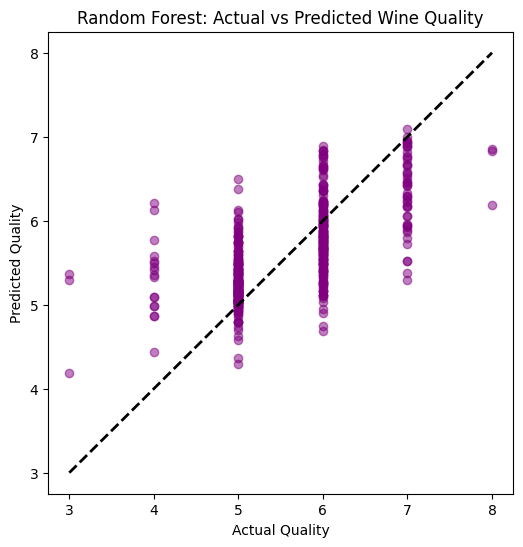

In [ ]:
# 5. 5-Fold Cross-Validated R-squared
cv_lr = cross_val_score(LinearRegression(), X_train_scaled, y_train, cv=5, scoring='r2').mean()
cv_rf = cross_val_score(RandomForestRegressor(random_state=5898), X_train, y_train, cv=5, scoring='r2').mean()
print(f"5-Fold CV R2 -> Linear Regression: {cv_lr:.3f}, Random Forest: {cv_rf:.3f}")

# Plot Actual vs Predicted for Random Forest (the better model)
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_rf, alpha=0.5, color='purple')
plt.xlabel("Actual Quality")
plt.ylabel("Predicted Quality")
plt.title("Random Forest: Actual vs Predicted Wine Quality")
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--', lw=2)
plt.show()


In [ ]:
# Install UCI repo tool if not already present
!pip install -q ucimlrepo

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd
import numpy as np

# 1. Load Raisin Dataset via official UCI repo ID (850)
raisin = fetch_ucirepo(id=850)
X_r = raisin.data.features
y_r = raisin.data.targets

# Combine into a single dataframe for EDA
df_raisin = X_r.copy()
df_raisin['Class'] = y_r['Class'].values

# EDA: Class distribution
print("--- Class Distribution ---")
print(df_raisin['Class'].value_counts())

# Preprocessing: Encode target labels to 0 and 1
le = LabelEncoder()
y_encoded = le.fit_transform(y_r.values.ravel())

# 2. Stratified Split (test_size = 0.3, random_state = 5898)
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_r, y_encoded, test_size=0.3, random_state=5898, stratify=y_encoded)

scaler_r = StandardScaler()
Xr_train_scaled = scaler_r.fit_transform(Xr_train)
Xr_test_scaled = scaler_r.transform(Xr_test)

# 3. Train Models
log_reg = LogisticRegression(random_state=5898)
log_reg.fit(Xr_train_scaled, yr_train)
y_pred_log = log_reg.predict(Xr_test_scaled)
y_prob_log = log_reg.predict_proba(Xr_test_scaled)[:, 1]

gnb = GaussianNB()
gnb.fit(Xr_train_scaled, yr_train)
y_pred_gnb = gnb.predict(Xr_test_scaled)
y_prob_gnb = gnb.predict_proba(Xr_test_scaled)[:, 1]

# Evaluation function
def evaluate_model(y_true, y_pred, y_prob):
    print("Confusion Matrix:\n", confusion_matrix(y_true, y_pred))
    print(f"Accuracy:  {accuracy_score(y_true, y_pred):.3f}")
    print(f"Precision: {precision_score(y_true, y_pred):.3f}")
    print(f"Recall:    {recall_score(y_true, y_pred):.3f}")
    print(f"F1-score:  {f1_score(y_true, y_pred):.3f}")
    print(f"ROC-AUC:   {roc_auc_score(y_true, y_prob):.3f}")

print("\n--- Logistic Regression Results ---")
evaluate_model(yr_test, y_pred_log, y_prob_log)

print("\n--- Gaussian Naive Bayes Results ---")
evaluate_model(yr_test, y_pred_gnb, y_prob_gnb)

# 4. Stratified Cross-Validation Scores
cv_log = cross_val_score(LogisticRegression(random_state=5898), Xr_train_scaled, yr_train, cv=5, scoring='f1').mean()
cv_gnb = cross_val_score(GaussianNB(), Xr_train_scaled, yr_train, cv=5, scoring='f1').mean()
print(f"\n5-Fold Stratified CV F1 -> Logistic Reg: {cv_log:.3f}, GNB: {cv_gnb:.3f}")

--- Class Distribution ---
Class
Kecimen    450
Besni      450
Name: count, dtype: int64

--- Logistic Regression Results ---
Confusion Matrix:
 [[119  16]
 [ 17 118]]
Accuracy:  0.878
Precision: 0.881
Recall:    0.874
F1-score:  0.877
ROC-AUC:   0.934

--- Gaussian Naive Bayes Results ---
Confusion Matrix:
 [[107  28]
 [  9 126]]
Accuracy:  0.863
Precision: 0.818
Recall:    0.933
F1-score:  0.872
ROC-AUC:   0.927

5-Fold Stratified CV F1 -> Logistic Reg: 0.866, GNB: 0.851


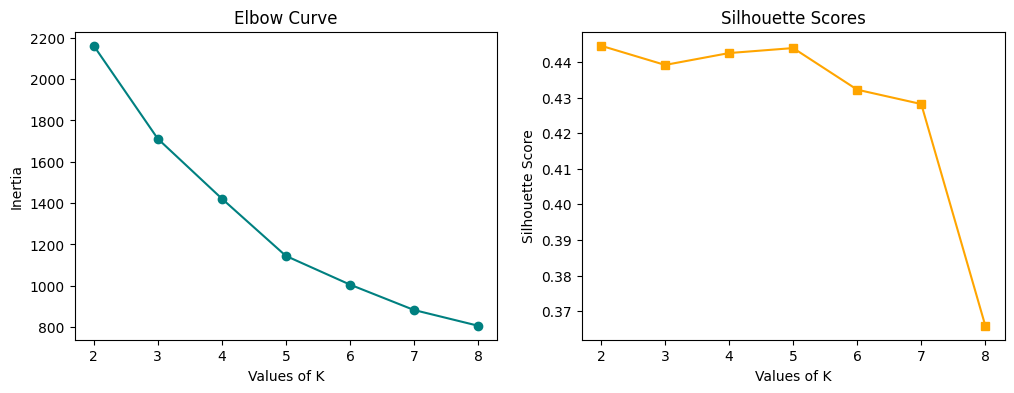


--- Cluster Profiles (Mean Values) ---
          Channel         Fresh          Milk       Grocery       Frozen  \
Cluster                                                                    
0        1.003367  13075.898990   3218.737374   3855.696970  3620.400673   
1        1.846154  25770.769231  35160.384615  41977.384615  6844.538462   
2        2.000000   8165.915385   8748.515385  13905.492308  1441.630769   

         Detergents_Paper   Delicassen  
Cluster                                 
0              776.875421  1242.249158  
1            19867.384615  7880.307692  
2             5991.146154  1535.007692  


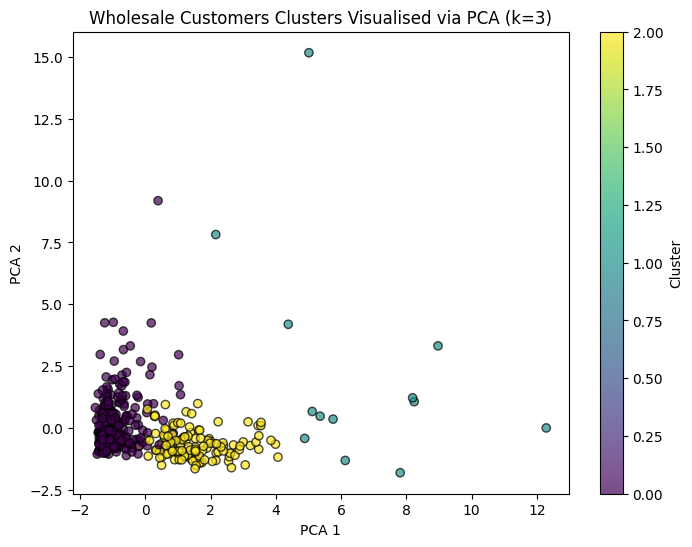

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# 1. Load Wholesale Customers Dataset via UCI repo ID (292)
wholesale_customers = fetch_ucirepo(id=292)
X_w = wholesale_customers.data.features

# Select numeric features and standardize
scaler_w = StandardScaler()
X_w_scaled = scaler_w.fit_transform(X_w)

# 2. Run k-means for k = 2 to 8
inertias = []
silhouette_scores = []
K_range = range(2, 9)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=5898, n_init=10)
    kmeans.fit(X_w_scaled)
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_w_scaled, kmeans.labels_))

# Plot Elbow Curve and Silhouette Scores
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(K_range, inertias, marker='o', color='teal')
plt.xlabel('Values of K')
plt.ylabel('Inertia')
plt.title('Elbow Curve')

plt.subplot(1, 2, 2)
plt.plot(K_range, silhouette_scores, marker='s', color='orange')
plt.xlabel('Values of K')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Scores')
plt.show()

# 3. Choose optimal k (e.g., k=3 based on standard wholesale dataset patterns)
optimal_k = 3
kmeans_opt = KMeans(n_clusters=optimal_k, random_state=5898, n_init=10)
clusters = kmeans_opt.fit_predict(X_w_scaled)

df_wholesale_profile = X_w.copy()
df_wholesale_profile['Cluster'] = clusters

# Profile each cluster (mean of each feature)
print("\n--- Cluster Profiles (Mean Values) ---")
print(df_wholesale_profile.groupby('Cluster').mean())

# 4. 2-D PCA Visualization
pca = PCA(n_components=2)
components = pca.fit_transform(X_w_scaled)

plt.figure(figsize=(8, 6))
plt.scatter(components[:, 0], components[:, 1], c=clusters, cmap='viridis', edgecolors='k', alpha=0.7)
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.title(f'Wholesale Customers Clusters Visualised via PCA (k={optimal_k})')
plt.colorbar(label='Cluster')
plt.show()